# Object-Oriented Programming (OOP)

## Inheritance

To avoid code repetition, it is common in the object-oriented paradigm to use inheritance.

Inheritance allows creating a new class using the properties of a previous class.

The parent class (the class from which inheritance occurs) is also called the __base__ class.

The child class (the class that inherits from another class) is also called the __derived__ class.

Syntax for defining an inherited class:

```
class DerivedClassName(BaseClassName):
    [ '''documentation line''' ]
    statements
```

In [1]:
class P: # base class
    a = 10 # static variable
    def __init__(self):
        self.b = 20 # instance variable
        
    def m1(self):
        print('Parent instance method')
        
    @classmethod
    def m2(cls):
        print('Parent class method')
        
    @staticmethod
    def m3():
        print('Parent static method')

class C(P): # derived class
    pass

c = C() # object c
print(c.a)
print(c.b)
c.m1()
c.m2()
c.m3()

10
20
Parent instance method
Parent class method
Parent static method


Forms of inheritance:
- Single – when the derived class inherits from only one base class;
- Multiple – when one derived class inherits from several base classes;
- Multilevel – the inheritance chain can consist of several base classes;
- Hierarchical – more than one derived class is created from one base class;
- Hybrid – combines more than one form of inheritance.

### Single inheritance

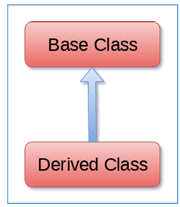

In [ ]:
# Base class
class Tree:
    def __init__(self, kind, height):
        self.kind = kind
        self.age = 0
        self.height = height
        
    def info(self):
        print ("{} years old {}. {} meters high.".format(self.age, self.kind,
                self.height))
        
    def grow(self):
        self.age += 1
        self.height += 0.5

t = Tree('oak', 0.2)
t.info()
t.grow()
t.info()

0 years old oak. 0.2 meters high.
1 years old oak. 0.7 meters high.


In [ ]:
# Derived class
class FruitTree(Tree):
    pass # class FruitTree has the attributes and methods of class Tree

ft = FruitTree('Apple', 0.2) # object ft
ft.grow()
ft.info()
print()

1 years old Apple. 0.7 meters high.



We supplement the derived class with a constructor (the `__init__()` method).

The `__init__()` method of the derived class overrides the inheritance of the `__init__()` method of the base class. To prevent this, the base class constructor must be called inside the derived class constructor.

In [ ]:
class FruitTree(Tree):
    def __init__(self, kind, height, give):
        Tree.__init__(self, kind, height) # the self parameter is required
        self.give = give
        
    def give_fruits(self):
        print ("Collected {} kg of {}s".format(self.give, self.kind))

ft = FruitTree('Apple', 0.2, 20)
ft.grow()
ft.info()
ft.give_fruits()

1 years old Apple. 0.7 meters high.
Collected 20 kg of Apples


Python has the `super()` method, which allows the derived class to call the methods and attributes of the base class:

In [ ]:
class FruitTree(Tree):
    def __init__(self, kind, height, give):
        super().__init__(kind, height) # the self parameter does not need to be included
        self.give = give
        
    def give_fruits(self):
        print ("Collected {} kg of {}s".format(self.give, self.kind))

ft = FruitTree('Apple', 0.2, 20)
ft.grow()
ft.info()
ft.give_fruits()

1 years old Apple. 0.7 meters high.
Collected 20 kg of Apples


### The `super()` method in single inheritance

In [6]:
class P: # base class
    a = 10 # static variable
    
    def __init__(self):
        print('Parent constructor')
        
    def m1(self):
        print('Parent instance method')
        
    @classmethod
    def m2(cls):
        print('Parent class method')
        
    @staticmethod
    def m3():
        print('Parent static method')

class C(P): # derived class
    def __init__(self):
        print('Child constructor')
        
    def method(self):
        print('Child method')
        super().__init__() # the base class constructor is called
        print(super().a) # a - the static variable of the base class
        super().m1() # the base class method m1 is called
        super().m2() # the base class method m2 is called
        super().m3() # the base class method m3 is called

c = C()
c.method()

Child constructor
Child method
Parent constructor
10
Parent instance method
Parent class method
Parent static method


Using the `super()` method, in a derived class it is only possible to access static variables.

In [7]:
class A:
    a = 111
    def __init__(self):
        self.b = 222

class B(A):
    a = 333
    def m1(self):
        print(B.a) # prints the static variable of the derived class
        print(super().a) # prints the static variable of the base class
        print(super().b) # error message

b = B()
b.m1()

333
111


<class 'AttributeError'>: 'super' object has no attribute 'b'

The instance variables of the base class can be accessed using the keyword `self`:

In [8]:
class A:
    a = 111
    def __init__(self):
        self.b = 222

class B(A):
    a = 333
    def m1(self):
        print(B.a) # prints the static variable of the derived class
        print(self.a) # prints the static variable of the derived class
        print(self.b) # prints the instance variable of the base class

b = B()
b.m1()

333
333
222


### Multilevel inheritance

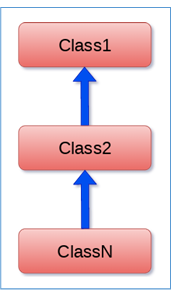

In [9]:
class Parent:
    def __init__(self):
        print('Parent klasė')

class Child(Parent):
    def __init__(self):
        print('Child klasė')
        Parent.__init__(self) # the class Parent constructor is called
        
    def info(self):
        print('Child klasės metodas')

class Grand_child(Child):
    def __init__(self):
        print('Grand_child klasė')
        Child.__init__(self) # the class Child constructor is called

grand_child_object = Grand_child()
print()
grand_child_object.info()

Grand_child klasė
Child klasė
Parent klasė

Child klasės metodas


The `super()` method in multilevel inheritance, when the names of the called methods are different:

In [10]:
class A:
    def m1(self):
        print('A method')

class B(A):
    def m2(self):
        print('B method')

class C(B):
    def m3(self):
        print('C method')

class D(C):
    def m1(self):
        print('D method')
        super().m1()
        super().m2()
        super().m3()

d = D()
d.m1()

D method
A method
B method
C method


The `super()` method in multilevel inheritance, when the names of the called methods are the same:

In [11]:
class A:
    def m1(self):
        print('A method')

class B(A):
    def m1(self):
        print('B method')

class C(B):
    def m1(self):
        print('C method')

class D(C):
    def m1(self):
        print('D method')

class E(D):
    def m1(self):
        print('E method')
        super().m1() # the super() method will call class D's method m1

e = E()
e.m1()

E method
D method


There are two ways to call methods of other classes from class E:
- `class_name.method_name(self)`, for example `B.m1(self)`
- `super(class_name, self).method_name()`, for example `super(B,self).m1()` (will call the superclass method of class B, i.e. class A's method m1).

In [12]:
class E(D):
    def m1(self):
        print('E method')
        super().m1()
        C.m1(self) # the class C method m1 is called
        super(B,self).m1() # the class A method m1 is called

e = E()
e.m1()

E method
D method
C method
A method


In [13]:
class Car:
    def __init__(self):
        print("You just created the car instance")
        
    def drive(self):
        print("Car started...")
        
    def stop(self):
        print("Car stopped")

class BMW(Car):
    def __init__(self):
        super().__init__() # the class Car constructor is called
        print("You just created the BMW instance")
        
    def drive(self):
        super().drive() # the class Car method drive() is called
        print("You are driving a BMW, Enjoy...")

class BMW320(BMW):
    def __init__(self):
        super().__init__() # the class BMW constructor is called
        print("You created BMW320 instance")
        
    def drive(self):
        super().drive() # the class BMW method drive() is called
        print("You are enjoying BMW 320")

b320 = BMW320()
b320.drive()
b320.stop()

You just created the car instance
You just created the BMW instance
You created BMW320 instance
Car started...
You are driving a BMW, Enjoy...
You are enjoying BMW 320
Car stopped


### Multiple Inheritance

Multiple inheritance is the case of inheritance when a derived class inherits from several base classes.

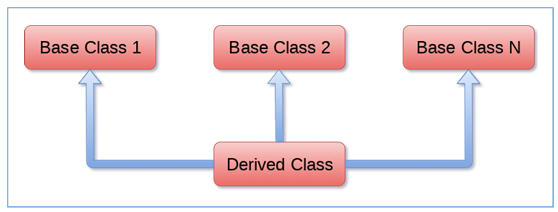

In [14]:
class Base_1:
    def __init__(self):
        print('Base_1')
        self.str_1 = 'Pagrindinė klasė Base_1'

class Base_2:
    def __init__(self):
        print('Base_2')
        self.str_2 = 'Pagrindinė klasė Base_2'

class Derived(Base_1, Base_2):
    def __init__(self):
        Base_1.__init__(self)
        Base_2.__init__(self)
        print('Derived')
        
    def str_info(self):
        print(self.str_1)
        print(self.str_2)

d_obj = Derived()
print()
d_obj.str_info()

Base_1
Base_2
Derived

Pagrindinė klasė Base_1
Pagrindinė klasė Base_2


### Method Resolution Order (MRO)

Method resolution order is the order in which methods with the same names should be inherited in the case of multiple inheritance. The resolution order can be seen with the help of the `__mro__` attribute or the `mro()` method. The attribute returns a tuple, the method returns a list.

In [15]:
class A():
    def m(self):
        print('A method')

class B():
    def m(self):
        print('B method')

class C:
    def m(self):
        print('C method')

class D(A,B,C):
    def m(self):
        print('D method')

print(D.__mro__) # the __mro__ attribute returns a tuple
print()
d = D()
d.m()

(<class '__main__.D'>, <class '__main__.A'>, <class '__main__.B'>, <class '__main__.C'>, <class 'object'>)

D method


In [16]:
class A():
    pass

class B():
    def m(self):
        print('B method')

class C:
    def m(self):
        print('C method')

class D(A,B,C):
    pass

print(D.mro()) # the mro() method returns a list
print()
d = D()
d.m()

[<class '__main__.D'>, <class '__main__.A'>, <class '__main__.B'>, <class '__main__.C'>, <class 'object'>]

B method


In [17]:
class A():
    def m(self):
        print('A method')

class B():
    def m(self):
        print('B method')

class C:
    pass

class D(C,A,B): # inheritance order changed (was D(A,B,C))
    pass

print(D.mro())
print()
d = D()
d.m()

[<class '__main__.D'>, <class '__main__.C'>, <class '__main__.A'>, <class '__main__.B'>, <class 'object'>]

A method


### The `__str__(self)` method

A method `__str__(self)` defined in a class allows controlling the output form.

The purpose of the `__str__(self)` method is to represent the object as a desired character string. If this method is not defined, Python uses the default string representation:

In [18]:
class Student:
    def __init__(self, name, mark):
        self.name = name
        self.mark = mark

s1 = Student('Mason', 9)
s2 = Student('Cooper', 10)
print(s1)
print(s2)

In [19]:
class Student:
    def __init__(self, name, mark):
        self.name = name
        self.mark = mark
        
    def __str__(self):
        return 'Name: {}\nMark: {}\n'.format(self.name, self.mark)

s1 = Student('Mason', 9)
s2 = Student('Cooper', 10)
print(s1)
print(s2)

Name: Mason
Mark: 9

Name: Cooper
Mark: 10



## Polymorphism

The concept of polymorphism – one name, but many forms.

Example of operator polymorphism:

In [20]:
# Here one operator "+" performs both addition and concatenation.
a = 10
b = 20
print(a + b)

eil_1 = 'Vienas'
eil_2 = 'Du'
print(eil_1 + eil_2)

30
VienasDu


Example of function polymorphism:

In [21]:
# Here the same function f performs operations with both two and three variables.
def f(a, b, z=0):
    return a + b + z

print(f(10, 20))
print(f(10, 20, 30))

30
60


Polymorphism in object-oriented programming is implemented by overloading a method or by overriding it.

Operator overloading is achieved using special methods (Magic methods):

| Operator | Method |
|---|---|
| + | `__add__(self, other)` |
| - | `__sub__(self, other)` |
| * | `__mul__(self, other)` |
| // | `__floordiv__(self, other)` |
| / | `__div__(self, other)` |
| % | `__mod__(self, other)` |
| ** | `__pow__(self, other)` |
| < | `__lt__(self, other)` |
| > | `__gt__(self, other)` |
| == | `__eq__(self, other)` |
| != | `__ne__(self, other)` |

More operator overloading methods can be found in the Python documentation.

The `__add__(self, other)` method:

In [22]:
class Book:
    def __init__(self, pages):
        self.pages = pages

b1 = Book(257)
b2 = Book(500)

print(b1 + b2) # the "+" operator cannot add objects of type 'Book'

<class 'TypeError'>: unsupported operand type(s) for +: 'Book' and 'Book'

In [23]:
class Book:
    def __init__(self, pages):
        self.pages = pages
        
    def __add__(self, other): # overloading of the "+" operator
        return self.pages + other.pages

b1 = Book(257)
b2 = Book(500)
print(b1 + b2) # an 'int' type value is obtained

757


If we try to add more attribute values, we will get an error message:

In [24]:
b1 = Book(257)
b2 = Book(500)
b3 = Book(321)
print(b1 + b2 + b3) # the "+" operator cannot add 'Book' and 'int' type objects

<class 'TypeError'>: unsupported operand type(s) for +: 'int' and 'Book'

To avoid the error, the `__add__(self, other)` method must return a value of type 'Book':

In [25]:
class Book:
    def __init__(self, pages):
        self.pages = pages
        
    def __add__(self, other):
        return Book(self.pages + other.pages) # a 'Book' type value is obtained
        
    def __str__(self):
        return 'Bendras puslapių skaičius: {}'.format(self.pages)

b1 = Book(257)
b2 = Book(500)
b3 = Book(321)
print(b1 + b2 + b3)

Bendras puslapių skaičius: 1078


The `__mul__(self, other)` method:

In [26]:
class Employee:
    def __init__(self, name, sal_per_day):
        self.name = name
        self.sal_per_day = sal_per_day
        
    def __mul__(self, other): # overloading of the "*" operator
        return self.sal_per_day * other.working_days

class TimeSheet:
    def __init__(self, name, working_days):
        self.name = name
        self.working_days = working_days

emp = Employee('Cooper', 100) # object emp
t_sh = TimeSheet('Cooper', 15) # object t_sh

print('Salary:', emp*t_sh)

Salary: 1500


The `__gt__(self, other)` method

In [27]:
class Student:
    def __init__(self, name, mark):
        self.name = name
        self.mark = mark
        
    def __gt__(self, other): # overloading of the ">" operator
        return self.mark > other.mark

s1 = Student('Mason', 9)
s2 = Student('Cooper', 10)
s3 = Student('Lee', 7)
print(s2 > s1)
print(s1 < s3)

True
False


If a class has the method `__gt__(self, other)`, the method `__lt__(self, other)` appears by default.

### Method overloading

In [28]:
class Test:
    def m(self, x):
        print(type(x))

t = Test()

# one method performs operations with different data types
t.m(10)
t.m(10.)
t.m('10')

<class 'int'>
<class 'float'>
<class 'str'>


In [29]:
class Test:
    def m(self, *args):
        sum = 0
        for i in args:
            sum += i
        print('suma =', sum)

t = Test()

# the method allows performing operations with a different number of arguments
t.m()
t.m(10)
t.m(1, 2, 3)

suma = 0
suma = 10
suma = 6


### Constructor overloading

In [31]:
class Hello:
    def __init__(self, name = None):
        self.name = name
        
    def say(self):
        if self.name is not None:
            print('Hello {}!'.format(self.name))
        else:
            print('Hello!')

h1 = Hello('John')
h1.say()

h2 = Hello()
h2.say()

Hello John!
Hello!


### Method overriding

Method overriding is the overriding, in inheriting classes, of methods described in the base class.

In [32]:
class A:
    def info(self):
        print('Klasės A metodas info')

class B(A):
    def info(self):
        print('Klasės B metodas info')

class C(B):
    def info(self):
        print('Klasės C metodas info')

a = A()
b = B()
c = C()

a.info()
b.info()
c.info()

Klasės A metodas info
Klasės B metodas info
Klasės C metodas info


In [33]:
class P:
    def __init__(self):
        self.value = 100
        
    def get_value(self):
        return self.value

class C(P):
    def get_value(self):
        return self.value + 1

c = C()
print(c.get_value())

101


## Encapsulation

In object-oriented programming, access to attributes and methods can be restricted. This is called encapsulation. Encapsulation prevents an object from being changed in an unintended way.

In Python, protected and private attributes and methods are used for object encapsulation.

### Private attributes

A private attribute is one that is used only inside the class and is not accessible "from the outside". Python implements this concept as follows:

if an identifier starts with two underscores – `__varName`, then the interpreter automatically adds the class name to it – `_ClassName__varName`.

In [34]:
class Rectangle:
    def __init__(self, height, width):
        self.__height = height
        self.__width = width

rect = Rectangle(10, 20)
print(rect.__width)

<class 'AttributeError'>: 'Rectangle' object has no attribute '__width'

After changing the attribute name:

In [35]:
print(rect._Rectangle__width) # _ClassName__varName

20


If the attribute identifier starts with two underscores, it can be accessed with the help of a method:

In [36]:
class Square:
    def __init__(self, side):
        self.__side = side

    def getSide (self):
        print(self.__side)
        
    def setSide(self, s):
        self.__side = s

rect = Square(100)
rect.getSide()

rect.__side = 5000 # attempting to change the value of the private variable
rect.getSide()

rect.setSide(250)
rect.getSide()

100
100
250


Private method:

In [37]:
class Test:
    def __m1(self): # private method
        print('Privatus metodas')

t = Test()
t.__m1() # calling a private method outside the class

<class 'AttributeError'>: 'Test' object has no attribute '__m1'

In [38]:
class Test:
    def __m1(self): # private method
        print('Privatus metodas')

t = Test()
t._Test__m1() # _ClassName__methodName

Privatus metodas


A private method can be called with the help of a non-private method:

In [39]:
class Test:
    def __m1(self): # private method
        print('Privatus metodas')
        
    def m2(self):
        self.__m1() # calling the private method

t = Test()
t.m2()

Privatus metodas


### Protected attributes

Attribute protection in Python is only a matter of convention. It is agreed that if an attribute's name starts with one underscore, it should not be accessed outside the class (except by a derived class), although this possibility exists.

In [40]:
class Rectangle:
    def __init__(self, height, width):
        self._height = height
        self._width = width

rect = Rectangle(10, 20)
print(rect._height) # by convention, the variable _height should not be accessed outside the class

10


### Private base class attributes in a derived class

In [41]:
class Base:
    def __init__(self):
        self.a = 10
        self.__b = 20

class Derived(Base):
    def display(self):
        print(self.a)
        print(self.__b) # will raise an error, since __b is a private variable of class Base

d = Derived()
d.display()

10


<class 'AttributeError'>: 'Derived' object has no attribute '_Derived__b'

In [42]:
class Base:
    def __private(self):
        print('Private value in Base')
        
    def _protected(self):
        print('Protected value in Base')
        
    def public(self):
        print('Public value in Base')
        self.__private() # a public method can only see its own class's private object
        self._protected()

class Derived(Base):
    def __private(self):
        print('Derived private')
        
    def _protected(self):
        print('Derived protected')

d = Derived()
d.public()

Public value in Base
Private value in Base
Derived protected
